# 02 - Adoption vs trust: descriptive analysis
Professional developers. Adoption base = answered the AI-use question. Trust base = current AI users (comparable across years).

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 80)

In [2]:
from src import descriptives as d
from src.viz import setup; setup()
full = pd.read_parquet("data/processed/respondents.parquet")
pro = full[full.is_professional == 1]
h = d.headline_table(pro); h.round(3)

,survey_year,n,share,n_eff,ci_low,ci_high,metric
0,2023,67237,0.442,67237.0,0.438,0.445,Adoption (uses AI)
1,2024,46853,0.633,46853.0,0.628,0.637,Adoption (uses AI)
2,2025,26045,0.808,26045.0,0.803,0.812,Adoption (uses AI)
3,2023,29595,0.463,29595.0,0.458,0.469,Trust (AI users)
4,2024,29379,0.414,29379.0,0.409,0.420,Trust (AI users)
5,2025,20775,0.384,20775.0,0.377,0.390,Trust (AI users)
6,2023,29595,0.251,29595.0,0.246,0.256,Distrust (AI users)
7,2024,29379,0.313,29379.0,0.308,0.319,Distrust (AI users)
8,2025,20775,0.380,20775.0,0.373,0.386,Distrust (AI users)


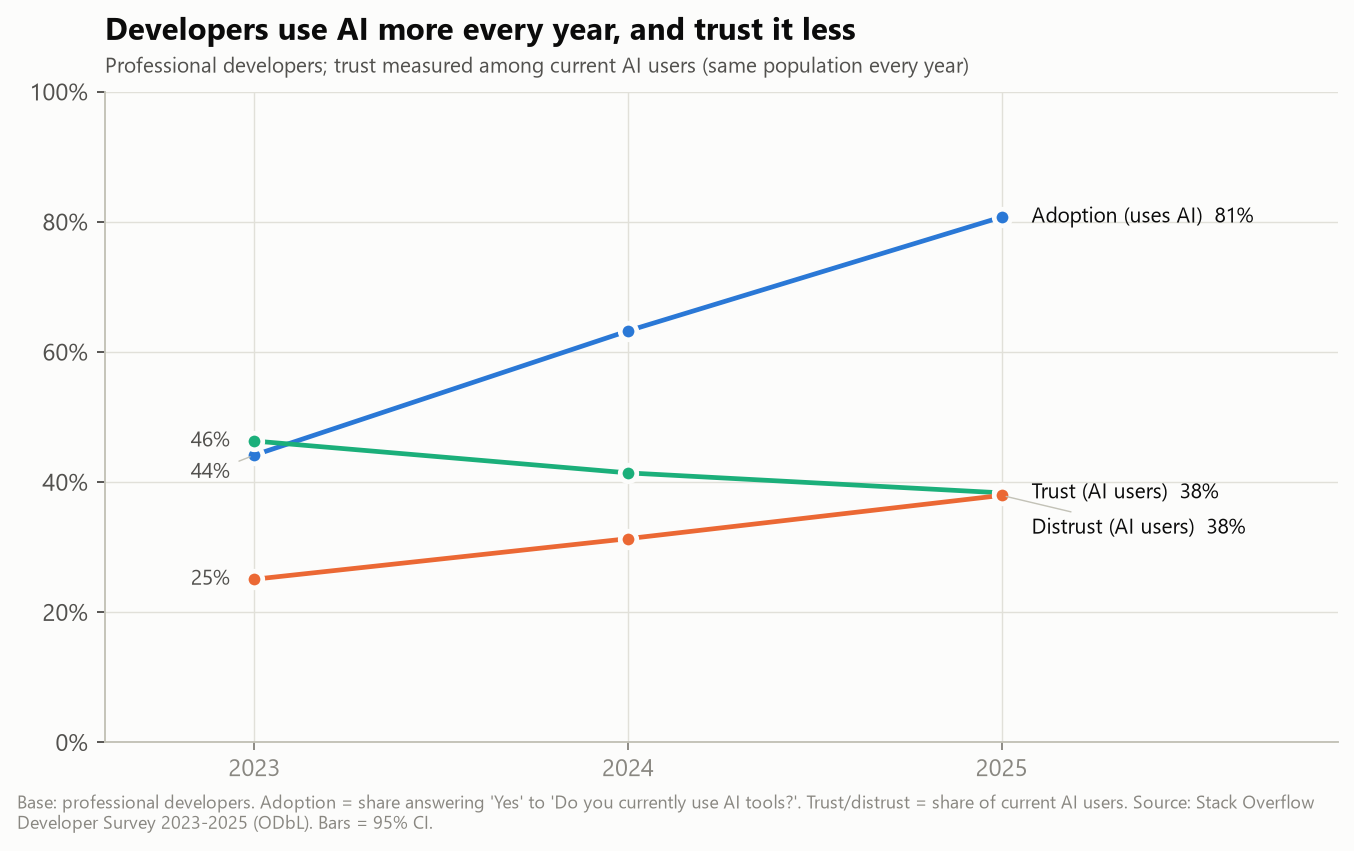

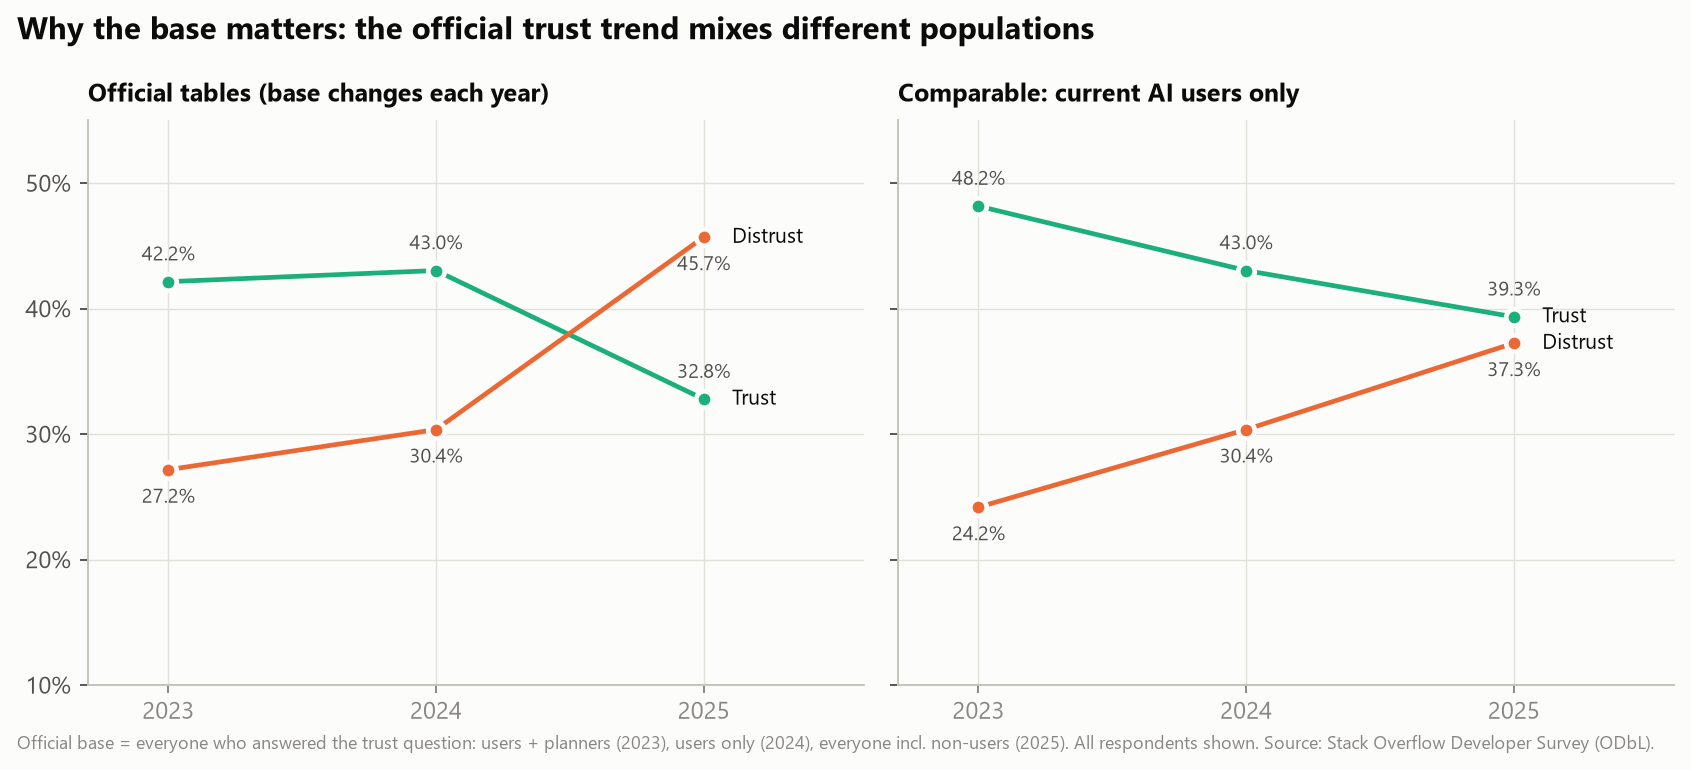

In [3]:
display(Image("reports/figures/fig01_adoption_vs_trust_trend.png", width=760))
display(Image("reports/figures/fig02_official_vs_comparable_trust.png", width=900))

## Segments
Distrust among AI users by experience, role, company size and country (95% Wilson CIs; n < 100 hidden).

In [4]:
seg = d.segment_table(pro)
seg[(seg.survey_year == 2025) & ~seg.suppressed].sort_values(["dimension", "distrust"]).round(3)

,dimension,survey_year,segment,n_adoption,adoption,n_trust,distrust,distrust_lo,distrust_hi,trust,suppressed
134,Age,2025,55+,1826,0.646,1169,0.347,0.321,0.375,0.423,False
133,Age,2025,45-54,3725,0.783,2897,0.378,0.360,0.396,0.385,False
131,Age,2025,25-34,9346,0.835,7674,0.381,0.370,0.392,0.389,False
132,Age,2025,35-44,7919,0.810,6369,0.382,0.370,0.394,0.378,False
130,Age,2025,18-24,3159,0.847,2623,0.383,0.365,0.402,0.365,False
27,Company size,2025,1 Solo / freelancer,835,0.792,650,0.306,0.272,0.343,0.466,False
28,Company size,2025,2 Under 20,3772,0.830,3090,0.365,0.349,0.383,0.389,False
29,Company size,2025,3 20-99,4648,0.828,3805,0.378,0.363,0.394,0.383,False
30,Company size,2025,4 100-999,5811,0.809,4644,0.382,0.368,0.396,0.377,False
32,Company size,2025,6 10k+,3193,0.803,2540,0.396,0.377,0.415,0.388,False


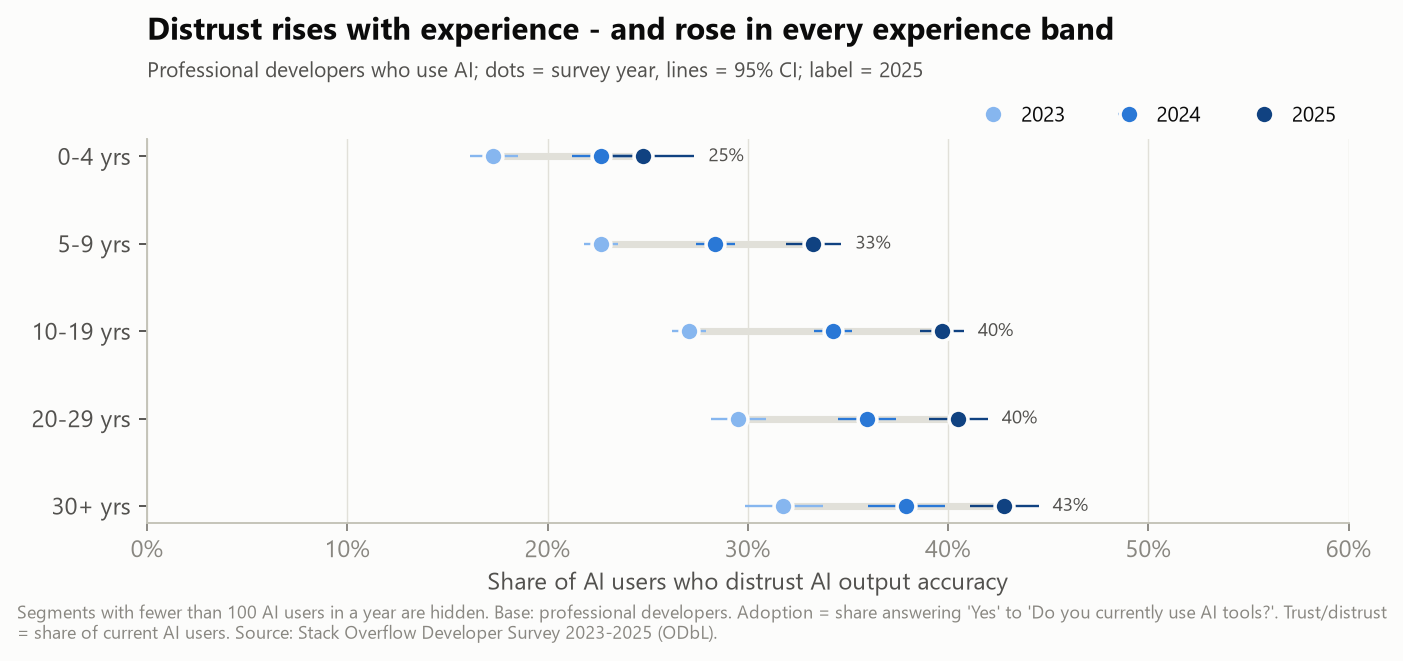

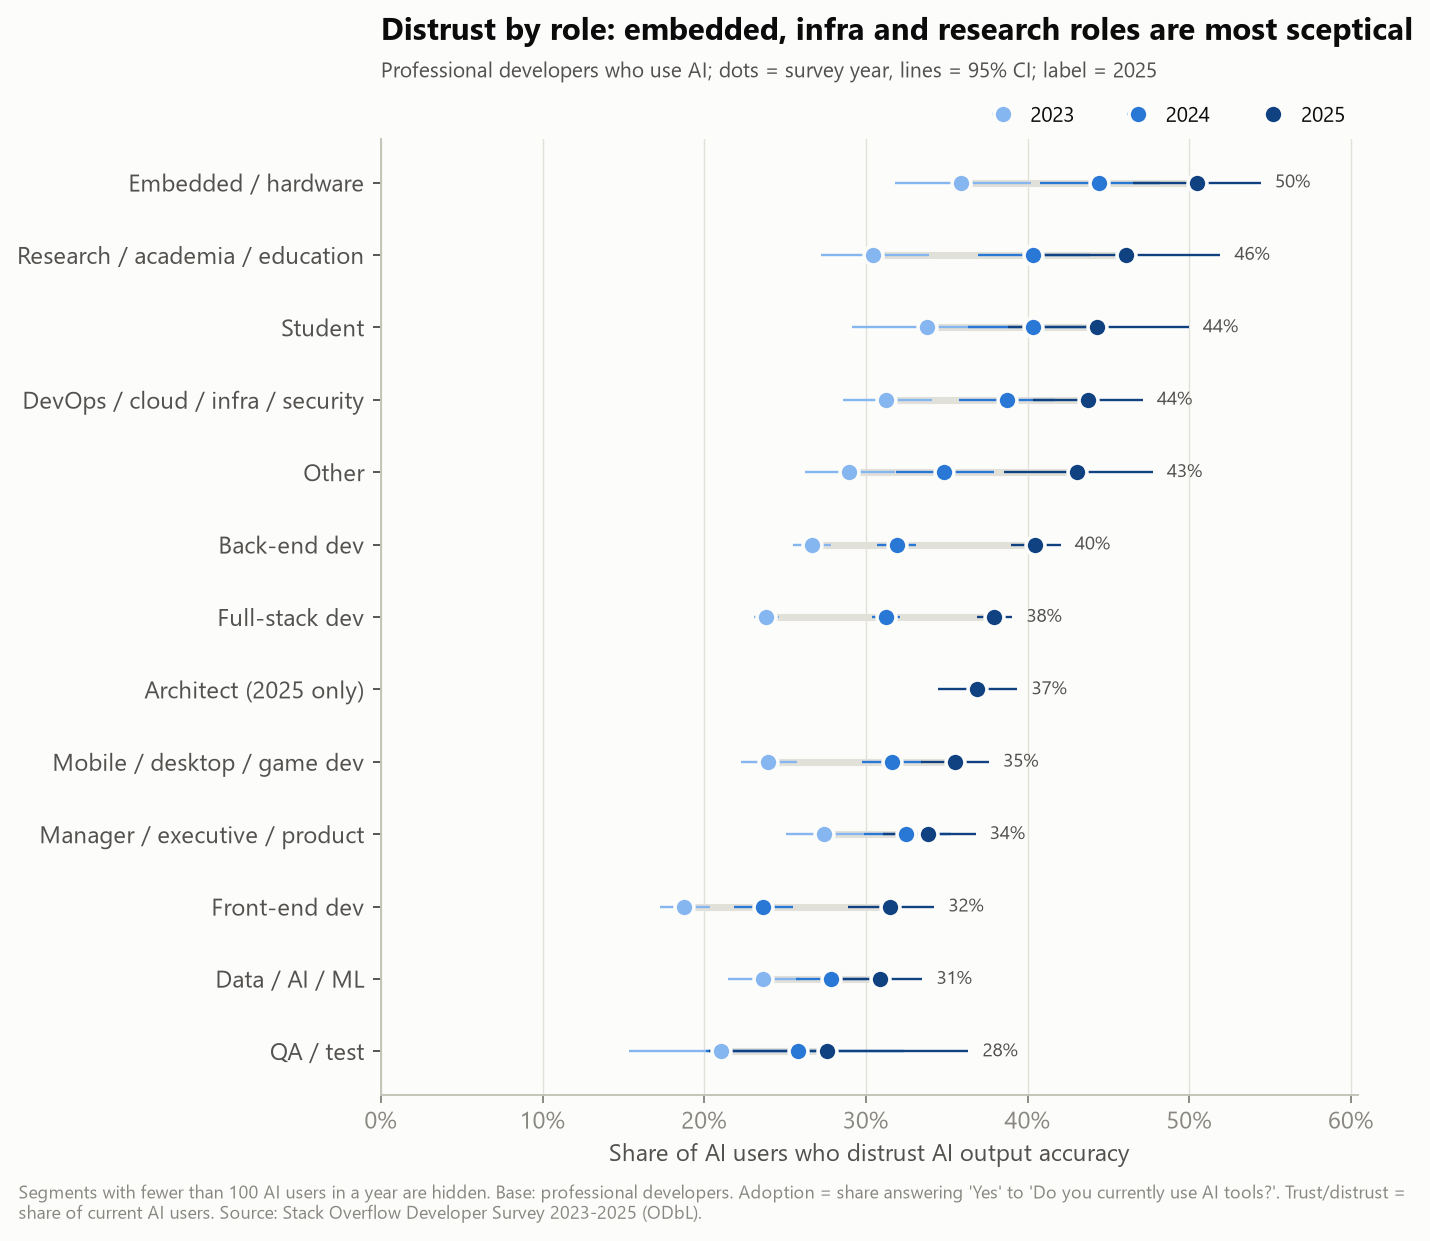

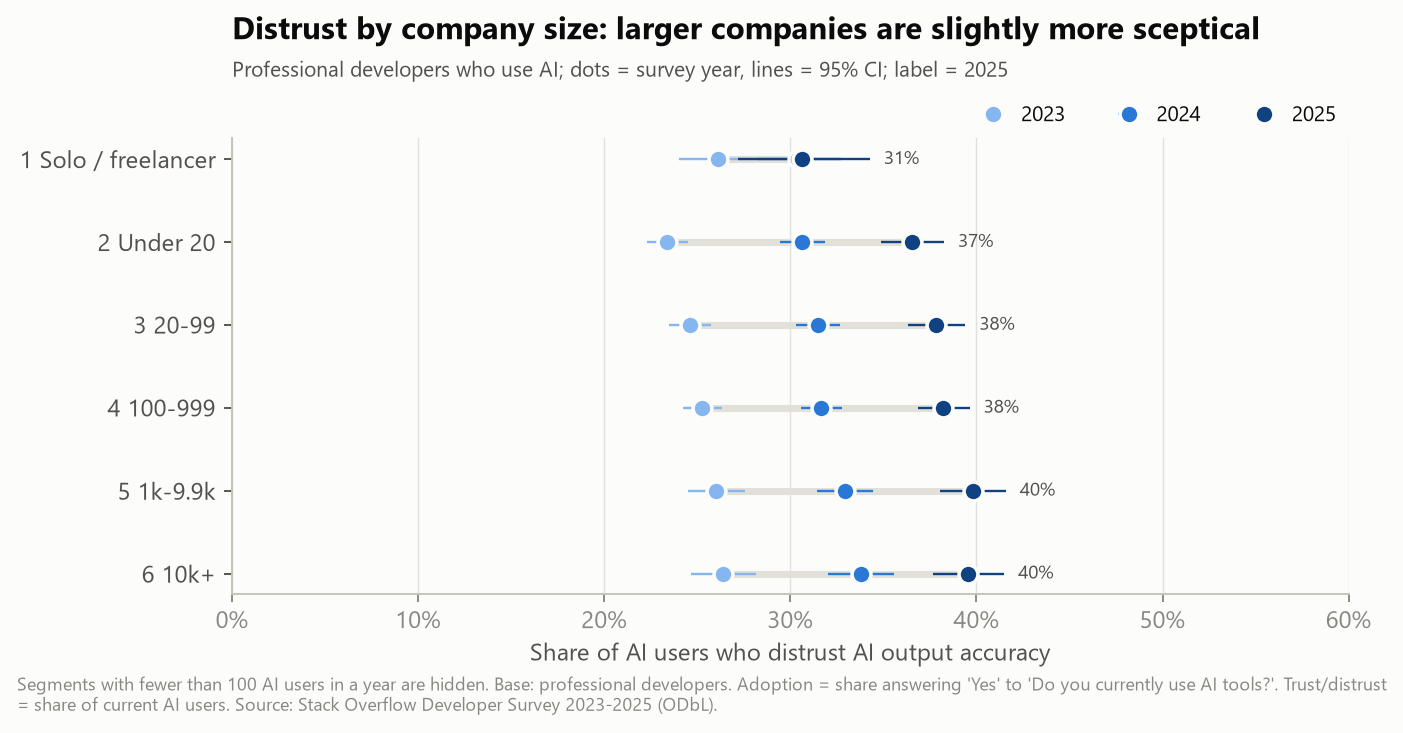

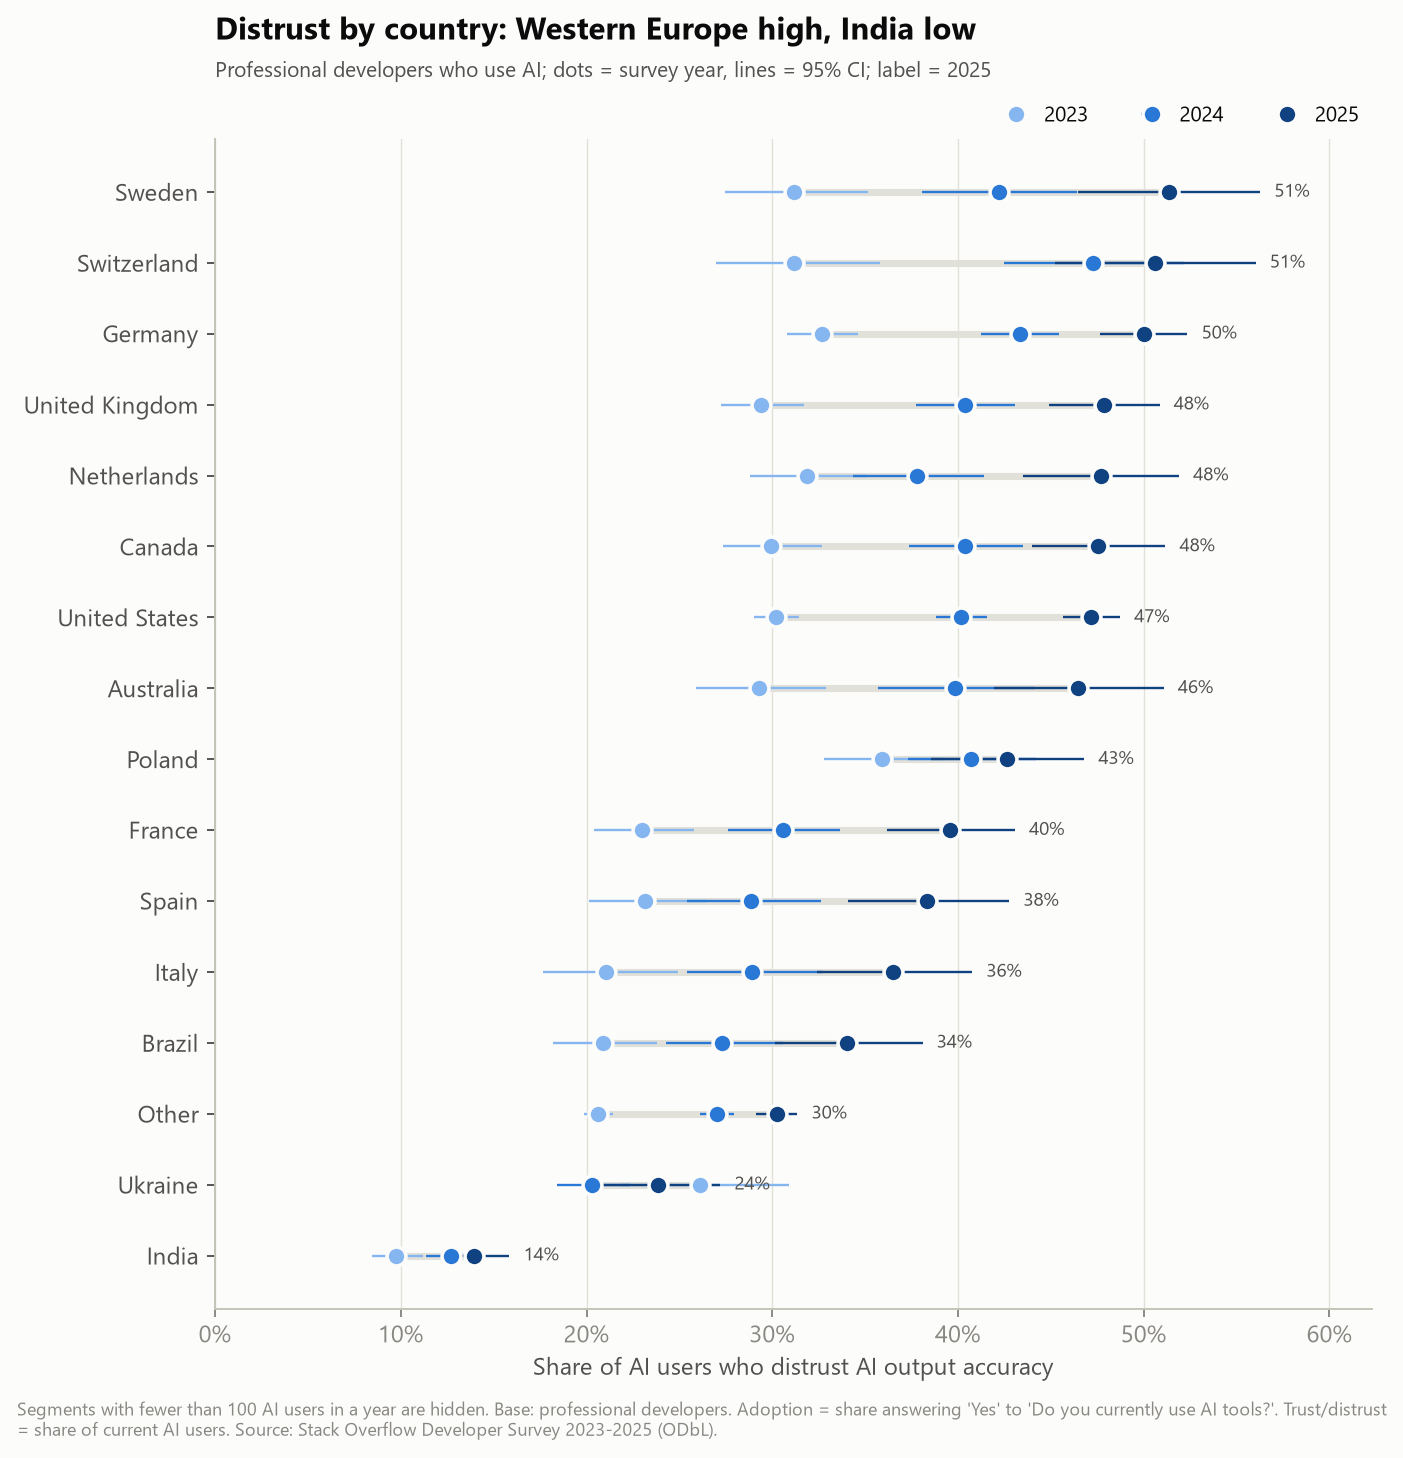

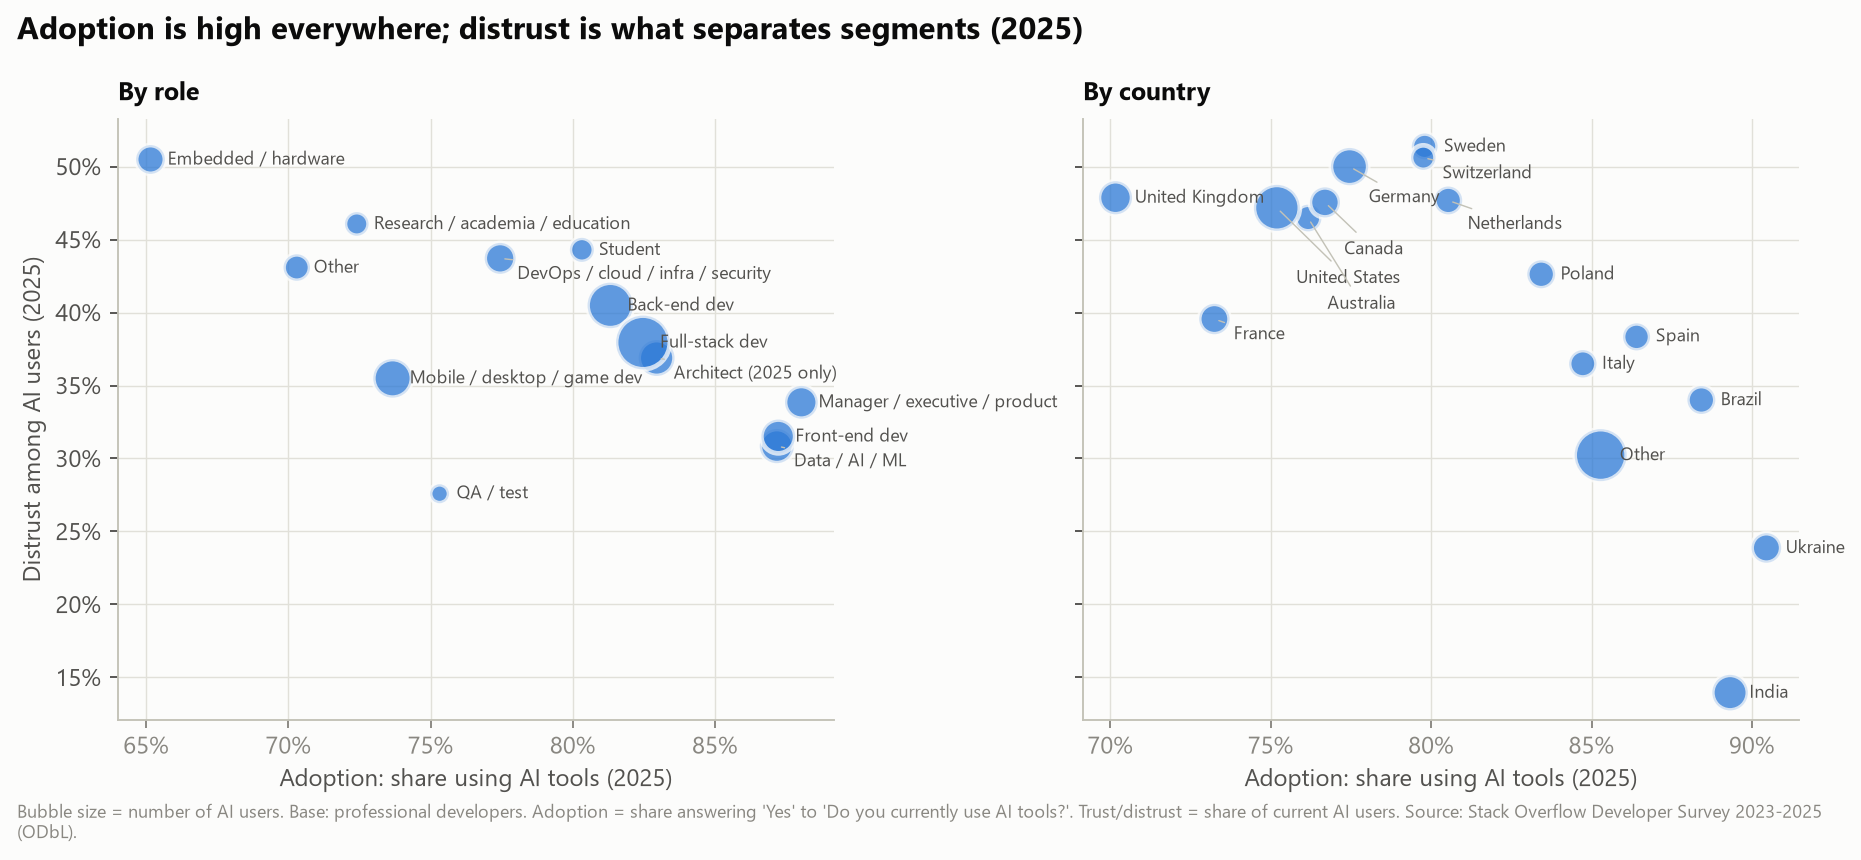

In [5]:
for f in ["fig03_distrust_by_experience", "fig04_distrust_by_role", "fig05_distrust_by_company_size",
          "fig06_distrust_by_country", "fig07_adoption_vs_distrust_segments_2025"]:
    display(Image(f"reports/figures/{f}.png", width=820))

## Type of AI use, use frequency, and the 2025 frustrations

In [6]:
display(d.task_table(pro).round(3))
display(d.frustration_table(pro).round(3))
display(d.frequency_table(pro).round(3))

,task,survey_year,n_users,share_using,distrust,distrust_not_using
0,writing_code,2023,23942,0.832,0.235,0.335
1,writing_code,2024,23515,0.827,0.294,0.419
2,writing_code,2025,11344,0.583,0.314,0.487
3,debugging,2023,13524,0.470,0.221,0.280
4,debugging,2024,15743,0.554,0.272,0.371
5,debugging,2025,9338,0.480,0.289,0.475
6,documenting_code,2023,10085,0.351,0.226,0.266
7,documenting_code,2024,11773,0.414,0.285,0.338
8,documenting_code,2025,7780,0.400,0.293,0.448
9,learning_codebase,2023,8188,0.285,0.189,0.277


,frustration,prevalence,n_yes,distrust_if_reported,distrust_if_not
0,almost_right,0.759,14971,0.389,0.381
1,debugging_slower,0.490,9668,0.481,0.296
3,less_confident,0.220,4330,0.317,0.407
4,hard_to_understand,0.157,3100,0.426,0.380
5,other,0.120,2369,0.576,0.361
2,not_regular_user,0.099,1954,0.578,0.366
6,no_problems,0.041,816,0.103,0.399


,dimension,segment,n,share,n_eff,ci_low,ci_high
0,AI use frequency,Daily,13019,0.276,13019.0,0.268,0.283
1,AI use frequency,Monthly or less,3276,0.655,3276.0,0.639,0.671
2,AI use frequency,Not using,4941,0.794,4941.0,0.782,0.805
3,AI use frequency,Weekly,4480,0.480,4480.0,0.466,0.495
4,AI agents (AI users),Copilot/autocomplete only,3321,0.395,3321.0,0.379,0.412
5,AI agents (AI users),No agents,8907,0.461,8907.0,0.450,0.471
6,AI agents (AI users),Uses agents,7655,0.295,7655.0,0.285,0.305


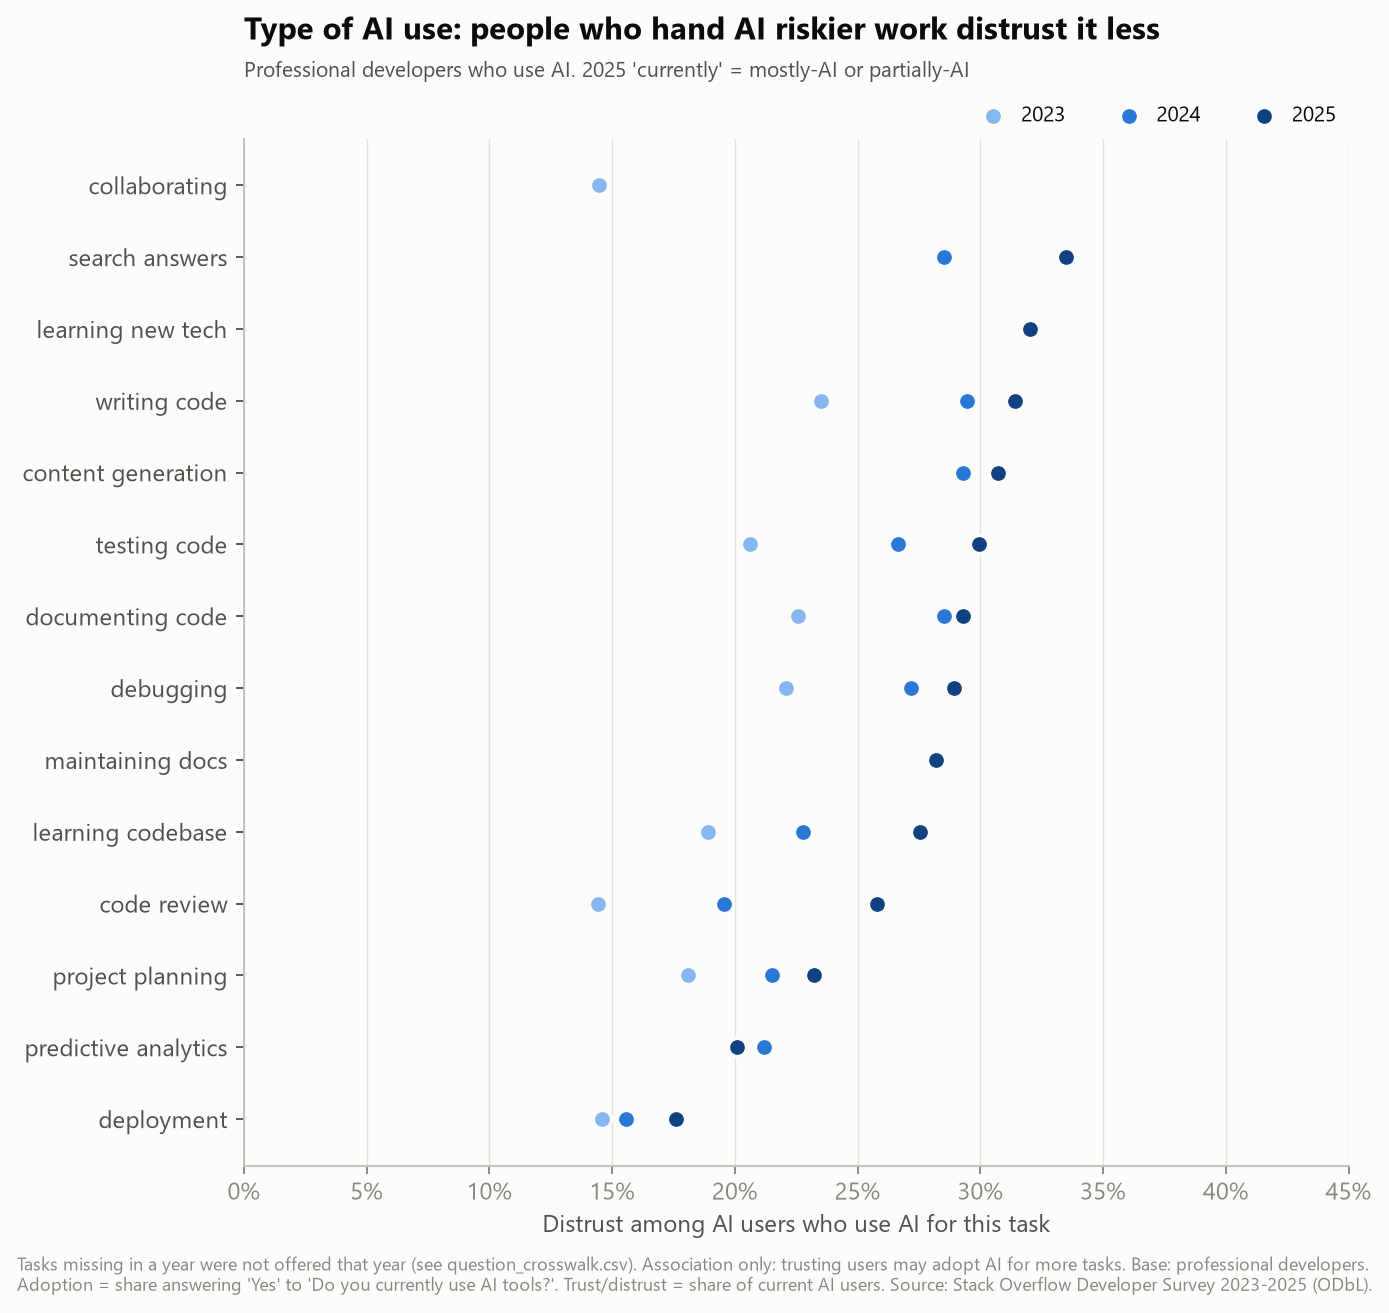

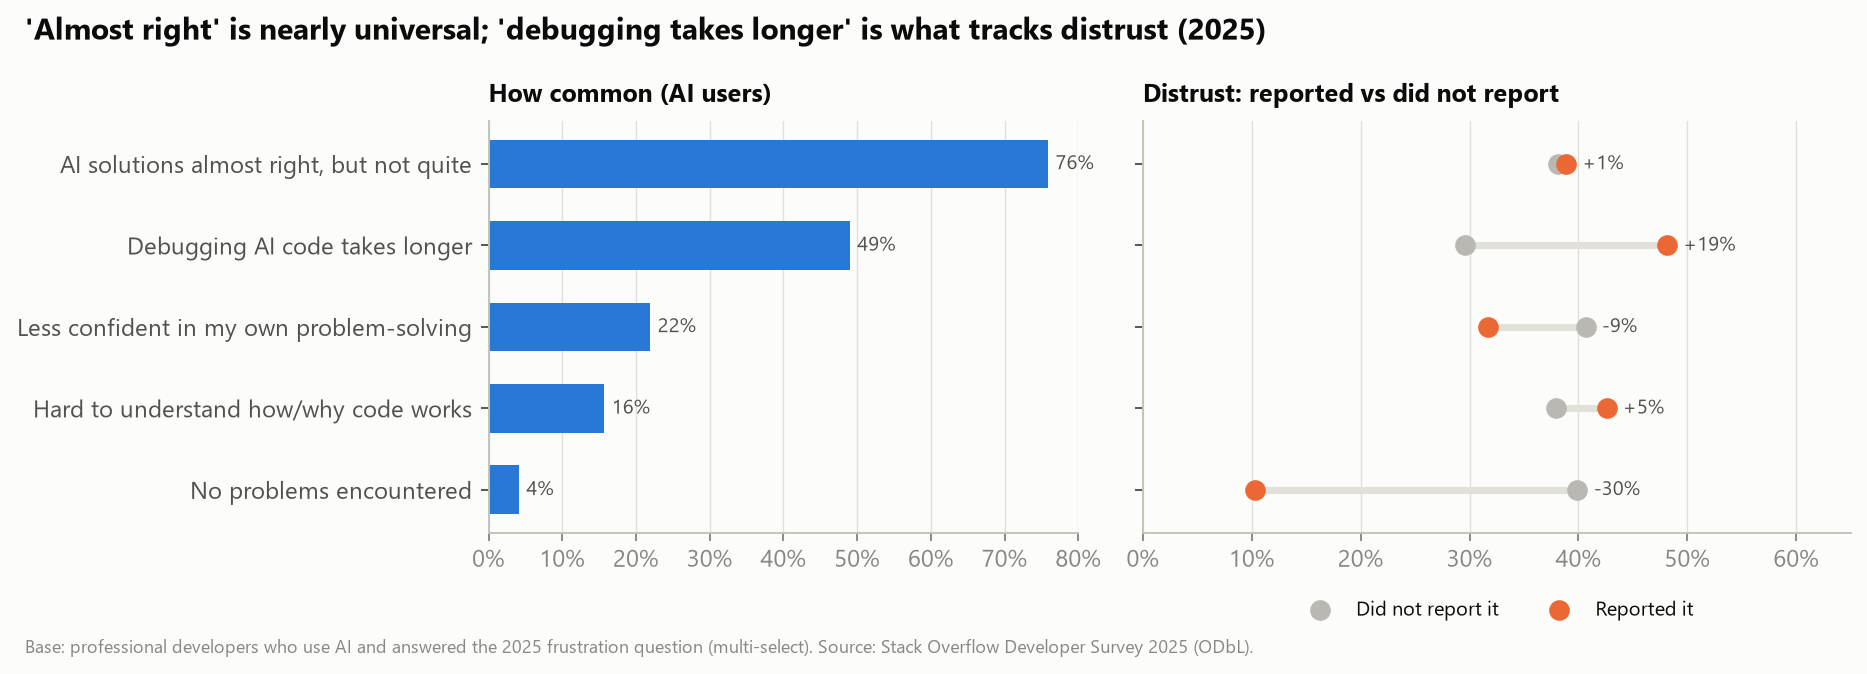

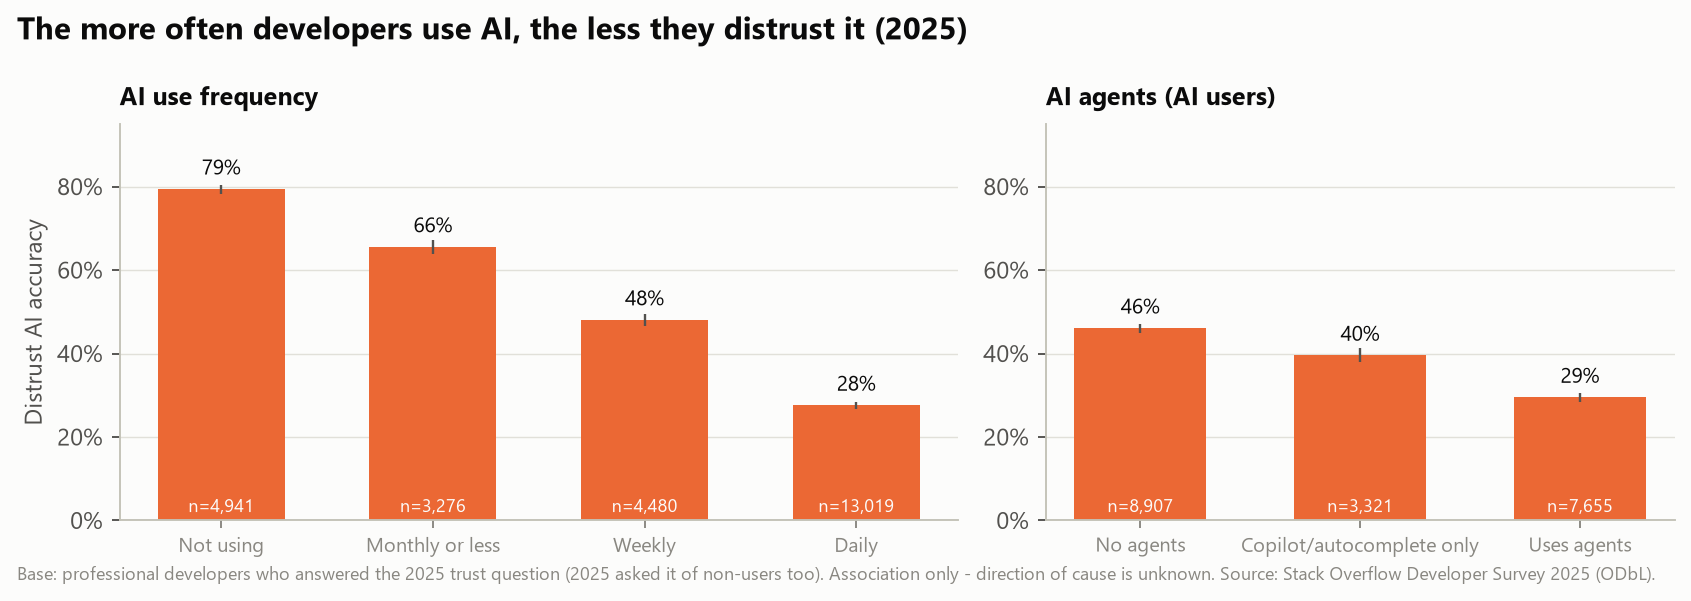

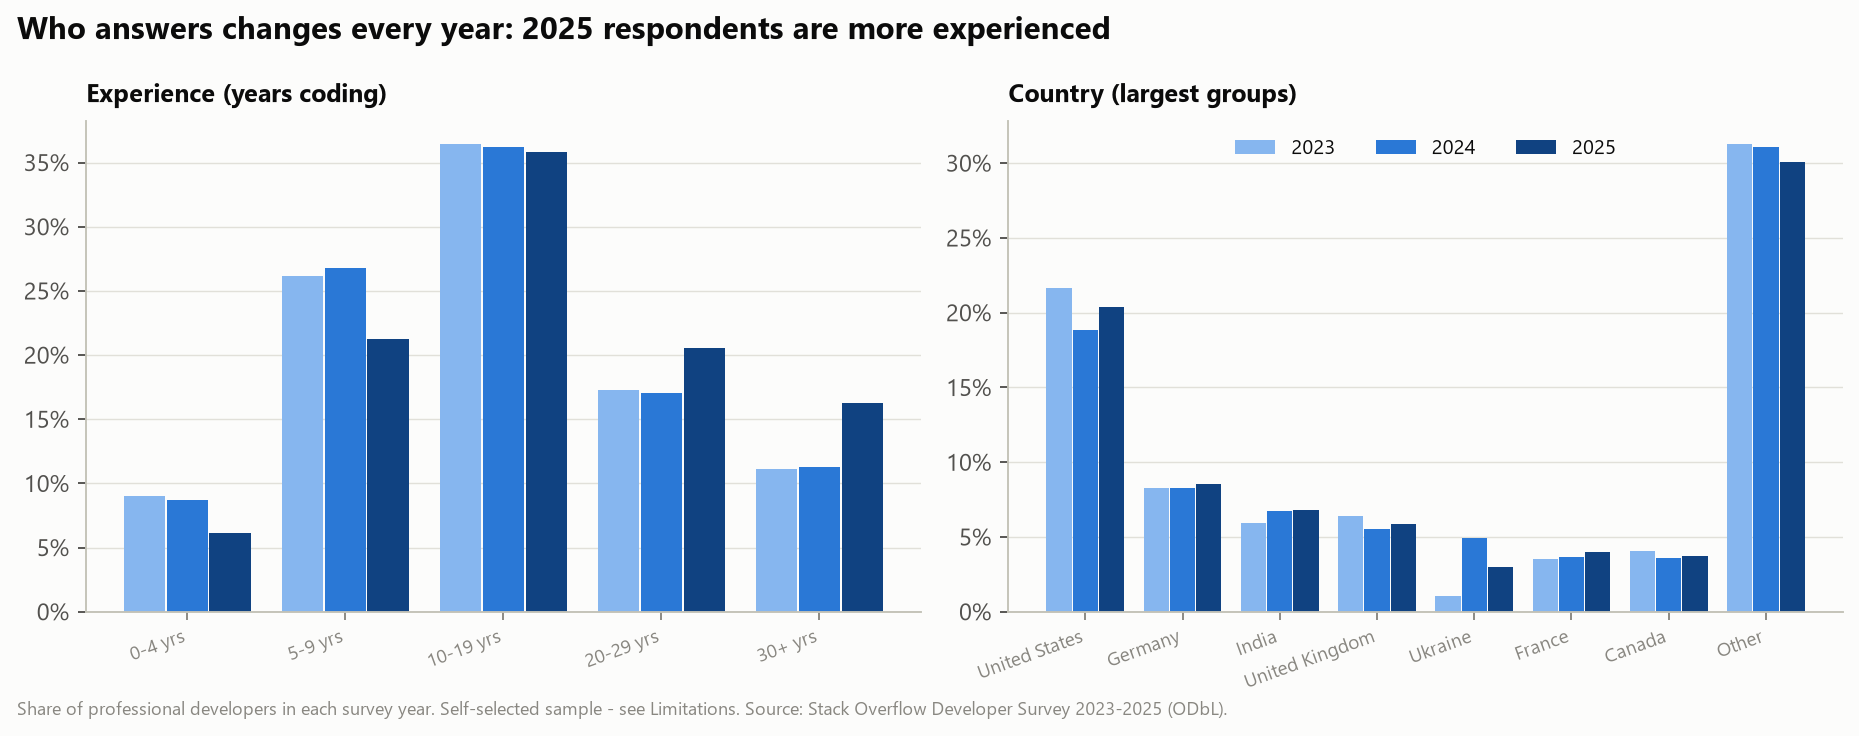

In [7]:
for f in ["fig08_distrust_by_ai_task", "fig09_frustrations_2025", "fig10_distrust_by_use_frequency_2025", "fig11_sample_composition"]:
    display(Image(f"reports/figures/{f}.png", width=860))